##**CH.SC.U4CSE24142 - SANTHOSH A - Regression and Classification**

## 1. Linear Regression
**Objective:** To implement Linear Regression using Python and understand model fitting, prediction, and evaluation.

**Scenario:** Predict product Sales based on advertisement spend on TV, Radio, and Newspaper.

Dataset Loaded successfully. First 5 rows:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


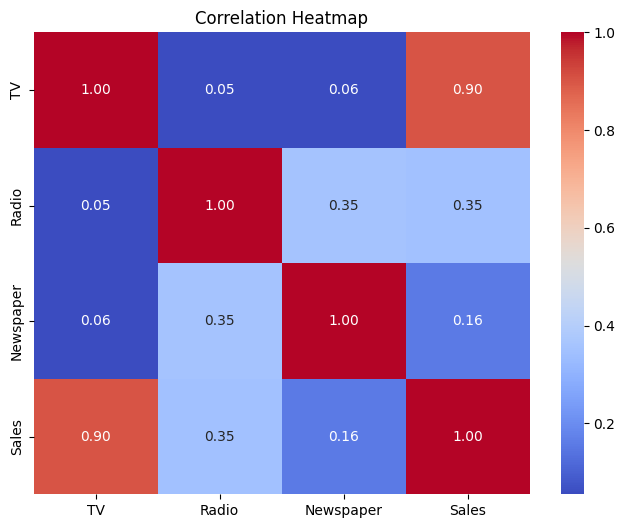

Linear Regression Evaluation:
MSE: 2.9078
R2 Score: 0.9059



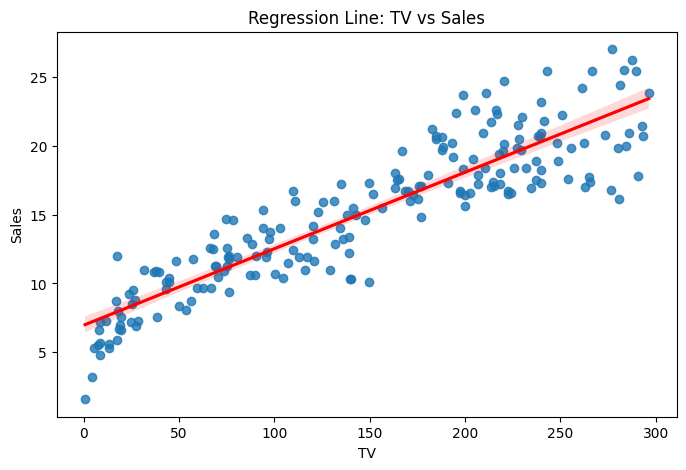

Polynomial Regression (Degree 2) Evaluation:
MSE: 1.4425
R2 Score: 0.9533


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

import warnings
warnings.filterwarnings('ignore')

# 1. Load the dataset
# Please download 'advertising.csv' from Kaggle and place it in the same directory.
# URL: https://www.kaggle.com/datasets/ashydv/advertising-dataset
try:
    df_adv = pd.read_csv('advertising.csv')
    print("Dataset Loaded successfully. First 5 rows:")
    display(df_adv.head())

    # Explore correlations
    plt.figure(figsize=(8, 6))
    sns.heatmap(df_adv.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.show()

    # 2. Split the dataset
    X = df_adv[['TV', 'Radio', 'Newspaper']]
    y = df_adv['Sales']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # 3. Fit Linear Regression
    lr = LinearRegression()
    lr.fit(X_train, y_train)

    # 4. Predict and calculate MSE and R2 score
    y_pred = lr.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"Linear Regression Evaluation:")
    print(f"MSE: {mse:.4f}")
    print(f"R2 Score: {r2:.4f}\n")

    # 5. Plot regression line for TV vs Sales
    plt.figure(figsize=(8, 5))
    sns.regplot(x='TV', y='Sales', data=df_adv, line_kws={"color": "red"})
    plt.title("Regression Line: TV vs Sales")
    plt.show()

    # 6. Polynomial Regression
    poly = PolynomialFeatures(degree=2)
    X_poly_train = poly.fit_transform(X_train)
    X_poly_test = poly.transform(X_test)

    poly_lr = LinearRegression()
    poly_lr.fit(X_poly_train, y_train)
    y_poly_pred = poly_lr.predict(X_poly_test)

    mse_poly = mean_squared_error(y_test, y_poly_pred)
    r2_poly = r2_score(y_test, y_poly_pred)
    print(f"Polynomial Regression (Degree 2) Evaluation:")
    print(f"MSE: {mse_poly:.4f}")
    print(f"R2 Score: {r2_poly:.4f}")

except FileNotFoundError:
    print("File 'advertising.csv' not found. Please download it from Kaggle and place it in the same directory.")


## 2. Multi Linear Regression
**Objective:** Perform Multi Linear Regression on the Pima Indian diabetes dataset.

1. Regression Equation:
Progression = 151.35 + (37.90 * age) + (-241.96 * sex) + (542.43 * bmi) + (347.70 * bp) + (-931.49 * s1) + (518.06 * s2) + (163.42 * s3) + (275.32 * s4) + (736.20 * s5) + (48.67 * s6)

2. Feature with the strongest impact: s1 (Coefficient: -931.49)

3. Model Evaluation:
MSE: 2900.1936 (Average squared error of predictions)
R2 Score: 0.4526 (Proportion of variance explained by the model)



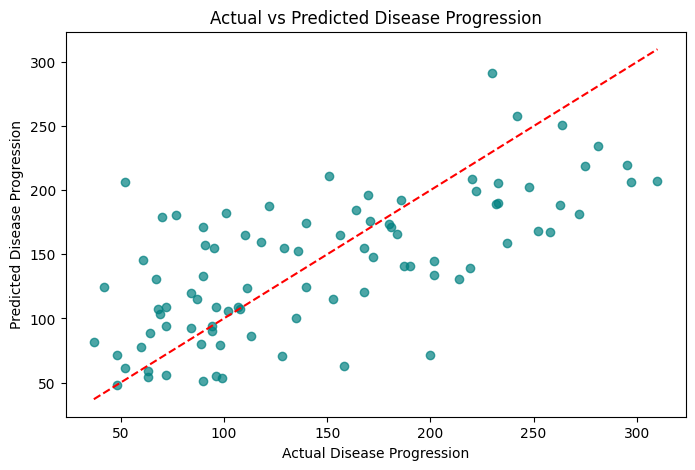

In [ ]:
from sklearn.datasets import load_diabetes

# Load diabetes dataset
diabetes = load_diabetes()
X_diab = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y_diab = diabetes.target

# Split the dataset
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_diab, y_diab, test_size=0.2, random_state=42)

# Fit Multi Linear Regression
mlr = LinearRegression()
mlr.fit(X_train_d, y_train_d)

# 1. Write the regression equation
coefs = mlr.coef_
intercept = mlr.intercept_
equation_terms = [f"({coef:.2f} * {name})" for coef, name in zip(coefs, X_diab.columns)]
equation = f"Progression = {intercept:.2f} + " + " + ".join(equation_terms)
print("1. Regression Equation:")
print(equation + "\n")

# 2. Identify strongest impact
# The strongest impact is the feature with the highest absolute coefficient
strongest_idx = np.argmax(np.abs(coefs))
strongest_feature = X_diab.columns[strongest_idx]
print(f"2. Feature with the strongest impact: {strongest_feature} (Coefficient: {coefs[strongest_idx]:.2f})\n")

# 3. Compute MSE and R2 score
y_pred_d = mlr.predict(X_test_d)
mse_d = mean_squared_error(y_test_d, y_pred_d)
r2_d = r2_score(y_test_d, y_pred_d)
print("3. Model Evaluation:")
print(f"MSE: {mse_d:.4f} (Average squared error of predictions)")
print(f"R2 Score: {r2_d:.4f} (Proportion of variance explained by the model)\n")

# 4. Visualize predicted vs actual
plt.figure(figsize=(8, 5))
plt.scatter(y_test_d, y_pred_d, alpha=0.7, color='teal')
plt.plot([y_test_d.min(), y_test_d.max()], [y_test_d.min(), y_test_d.max()], color='red', linestyle='--')
plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title("Actual vs Predicted Disease Progression")
plt.show()


## 3. Logistic Regression
**Scenario:** Healthcare Data Scientist predicting whether a tumor is malignant or benign.


Logistic Regression Performance:
Accuracy:  0.9561
Precision: 0.9459
Recall:    0.9859
F1-Score:  0.9655



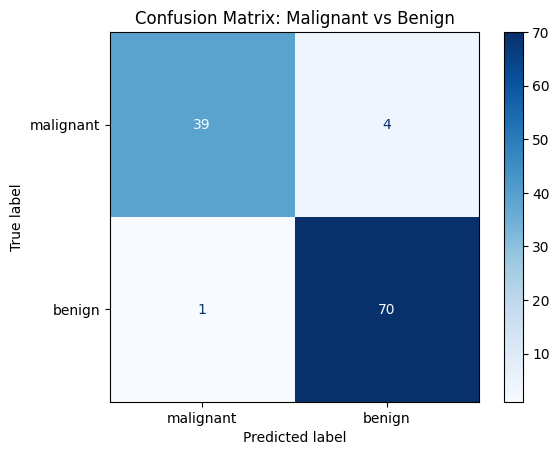

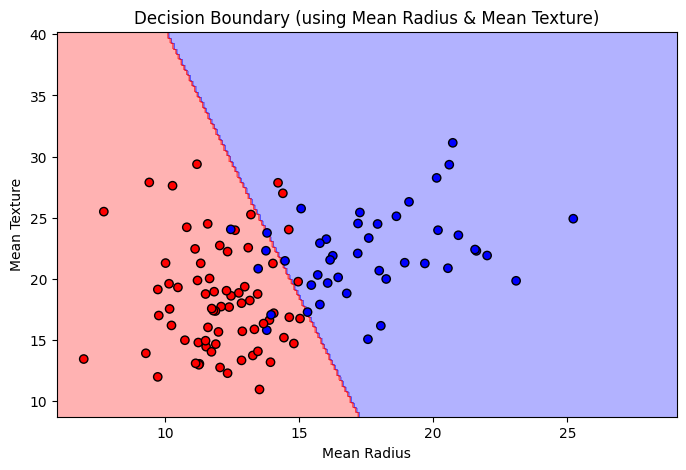

L1 Regularization Accuracy: 0.9561
L2 Regularization Accuracy: 0.9561


In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from matplotlib.colors import ListedColormap

# 1. Load dataset
cancer = load_breast_cancer()
X_bc = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y_bc = cancer.target

# 2. Split into training and testing sets
X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(X_bc, y_bc, test_size=0.2, random_state=42)

# 3. Train a Logistic Regression model
log_reg = LogisticRegression(max_iter=10000)
log_reg.fit(X_train_bc, y_train_bc)
y_pred_bc = log_reg.predict(X_test_bc)

# 4. Evaluate
print("Logistic Regression Performance:")
print(f"Accuracy:  {accuracy_score(y_test_bc, y_pred_bc):.4f}")
print(f"Precision: {precision_score(y_test_bc, y_pred_bc):.4f}")
print(f"Recall:    {recall_score(y_test_bc, y_pred_bc):.4f}")
print(f"F1-Score:  {f1_score(y_test_bc, y_pred_bc):.4f}\n")

# 5. Plot the confusion matrix
cm = confusion_matrix(y_test_bc, y_pred_bc)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix: Malignant vs Benign")
plt.show()

# 6. Visualize decision boundary (choose two features: mean radius and mean texture)
X_2d = X_bc[['mean radius', 'mean texture']].values
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(X_2d, y_bc, test_size=0.2, random_state=42)

log_reg_2d = LogisticRegression()
log_reg_2d.fit(X_train_2d, y_train_2d)

x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
Z = log_reg_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(('blue', 'red')))
plt.scatter(X_test_2d[:, 0], X_test_2d[:, 1], c=y_test_2d, edgecolor='k', cmap=ListedColormap(('blue', 'red')))
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Decision Boundary (using Mean Radius & Mean Texture)")
plt.show()

# 7. Experiment with regularization (L1, L2)
log_reg_l1 = LogisticRegression(penalty='l1', solver='liblinear', max_iter=10000, random_state=42)
log_reg_l1.fit(X_train_bc, y_train_bc)
print(f"L1 Regularization Accuracy: {log_reg_l1.score(X_test_bc, y_test_bc):.4f}")

log_reg_l2 = LogisticRegression(penalty='l2', max_iter=10000, random_state=42)
log_reg_l2.fit(X_train_bc, y_train_bc)
print(f"L2 Regularization Accuracy: {log_reg_l2.score(X_test_bc, y_test_bc):.4f}")



## 4. Naïve Bayes Classification
**Scenario:** Building a Spam Filter for an Email Service.


Dataset downloaded and extracted.
Multinomial Naive Bayes (Spam Detection) Performance:
Accuracy:  0.9785
Precision: 1.0000
Recall:    0.8389



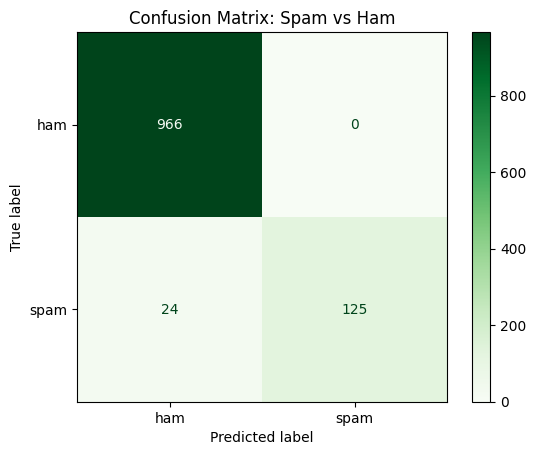

GaussianNB (Iris Dataset) Accuracy: 1.0000
BernoulliNB (Spam Dataset) Accuracy: 0.9776

Top 10 words indicative of Spam: free, txt, mobile, text, claim, stop, reply, ur, www, prize
Top 10 words indicative of Ham:  ok, ll, come, lt, gt, just, good, home, time, later

MultinomialNB with Feature Selection (max_features=500) Accuracy: 0.9794


In [ ]:
import urllib.request
import zipfile
import os
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB, GaussianNB, BernoulliNB
from sklearn.datasets import load_iris

# Download and extract dataset if it doesn't exist
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
zip_path = "smsspamcollection.zip"
data_path = "SMSSpamCollection"

if not os.path.exists(data_path):
    print("Downloading SMS Spam Collection dataset...")
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")
    print("Dataset downloaded and extracted.")

# 1. Load dataset and preprocess
df_spam = pd.read_csv(data_path, sep='\t', header=None, names=['label', 'message'])
df_spam['label_num'] = df_spam.label.map({'ham': 0, 'spam': 1})

X_text = df_spam['message']
y_text = df_spam['label_num']

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_text, y_text, test_size=0.2, random_state=42)

# 2. Convert text to numerical features using TF-IDF
tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train_t)
X_test_tfidf = tfidf.transform(X_test_t)

# 3. Train a Multinomial Naïve Bayes classifier
mnb = MultinomialNB()
mnb.fit(X_train_tfidf, y_train_t)
y_pred_mnb = mnb.predict(X_test_tfidf)

# 4. Evaluate performance
print("Multinomial Naive Bayes (Spam Detection) Performance:")
print(f"Accuracy:  {accuracy_score(y_test_t, y_pred_mnb):.4f}")
print(f"Precision: {precision_score(y_test_t, y_pred_mnb):.4f}")
print(f"Recall:    {recall_score(y_test_t, y_pred_mnb):.4f}\n")

# Plot confusion matrix
cm_mnb = confusion_matrix(y_test_t, y_pred_mnb)
disp_mnb = ConfusionMatrixDisplay(confusion_matrix=cm_mnb, display_labels=['ham', 'spam'])
disp_mnb.plot(cmap='Greens')
plt.title("Confusion Matrix: Spam vs Ham")
plt.show()

# 5. Compare GaussianNB, MultinomialNB, and BernoulliNB
# GaussianNB on Iris Dataset
iris = load_iris()
X_ir_train, X_ir_test, y_ir_train, y_ir_test = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42)
gnb = GaussianNB()
gnb.fit(X_ir_train, y_ir_train)
print(f"GaussianNB (Iris Dataset) Accuracy: {gnb.score(X_ir_test, y_ir_test):.4f}")

# BernoulliNB on Spam Dataset
bnb = BernoulliNB()
bnb.fit(X_train_tfidf, y_train_t)
print(f"BernoulliNB (Spam Dataset) Accuracy: {bnb.score(X_test_tfidf, y_test_t):.4f}\n")

# 6. Visualize word distributions (Top words in spam vs ham)
feature_names = np.array(tfidf.get_feature_names_out())

# Sort log probabilities of words for spam (class 1)
sorted_spam_idx = mnb.feature_log_prob_[1].argsort()[::-1]
top_spam_words = feature_names[sorted_spam_idx[:10]]

# Sort log probabilities of words for ham (class 0)
sorted_ham_idx = mnb.feature_log_prob_[0].argsort()[::-1]
top_ham_words = feature_names[sorted_ham_idx[:10]]

print(f"Top 10 words indicative of Spam: {', '.join(top_spam_words)}")
print(f"Top 10 words indicative of Ham:  {', '.join(top_ham_words)}\n")

# 7. Experiment with feature selection (e.g. limiting max_features)
tfidf_fs = TfidfVectorizer(stop_words='english', max_features=500)
X_train_fs = tfidf_fs.fit_transform(X_train_t)
X_test_fs = tfidf_fs.transform(X_test_t)

mnb_fs = MultinomialNB()
mnb_fs.fit(X_train_fs, y_train_t)
print(f"MultinomialNB with Feature Selection (max_features=500) Accuracy: {mnb_fs.score(X_test_fs, y_test_t):.4f}")

